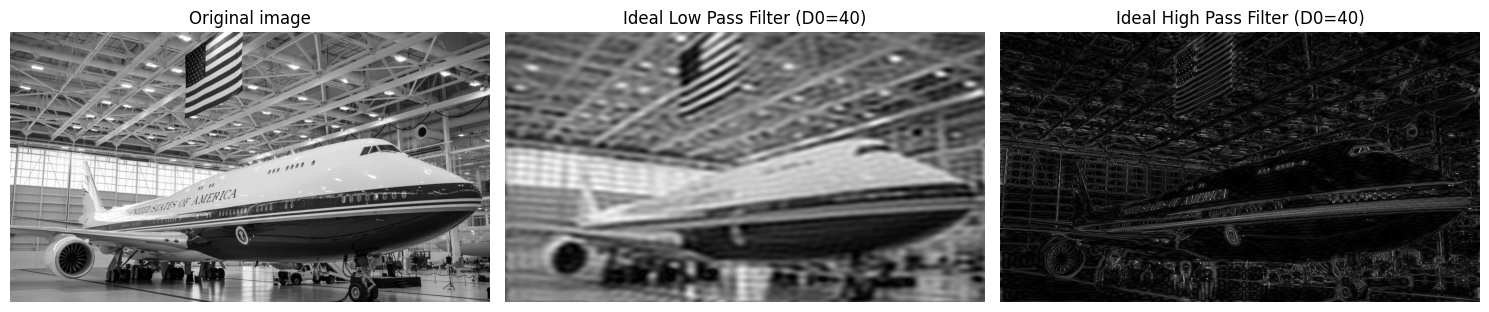

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

#Read image in grayscale
img = cv2.imread(r"C:\Users\janar\Digital Image Processing\Images\AF1.jpg",0)
img_float = np.float32(img)

#1.Compute DFT and Shift origin to center
dft = cv2.dft(img_float,flags=cv2.DFT_COMPLEX_OUTPUT)
dft_shift=np.fft.fftshift(dft)

rows,cols = img.shape
crow,ccol = rows//2,cols//2#Center coordinates

#Define a cutoff frequency (radius)
D0 = 40

#2.Create Ideal Low Pass Filter(ILPF) mask
mask_ilpf = np.zeros((rows,cols,2),np.uint8)
for u in range(rows):
    for v in range(cols):
        D = np.sqrt((u - crow)**2 + (v - ccol)**2)
        if D<=D0:
            mask_ilpf[u,v] = 1
#3. Create Ideal High Pass Filter(IHPF) mask
mask_ihpf = np.ones((rows,cols,2),np.uint8)
for u in range(rows):
    for v in range(cols):
        D=np.sqrt((u - crow)**2 + (v - ccol)**2)
        if D <= D0:
            mask_ihpf[u,v]=0
#4.Apply masks and compute Inverse DFT
#Apply Low Pass Filter
fshift_ilpf = dft_shift * mask_ilpf
f_ishift_ilpf = np.fft.ifftshift(fshift_ilpf)
img_back_ilpf = cv2.idft(f_ishift_ilpf)
img_back_ilpf = cv2.magnitude(img_back_ilpf[:,:,0], img_back_ilpf[:,:,1])

#Apply High Pass Filter
fshift_ihpf = dft_shift * mask_ihpf
f_ishift_ihpf = np.fft.ifftshift(fshift_ihpf)
img_back_ihpf = cv2.idft(f_ishift_ihpf)
img_back_ihpf = cv2.magnitude(img_back_ihpf[:,:,0], img_back_ihpf[:,:,1])

#Display the results
plt.figure(figsize=(15,6))

plt.subplot(1,3,1)
plt.imshow(img, cmap='gray')
plt.title('Original image')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(img_back_ilpf, cmap='gray')
plt.title(f'Ideal Low Pass Filter (D0={D0})')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(img_back_ihpf, cmap='gray')
plt.title(f'Ideal High Pass Filter (D0={D0})')
plt.axis('off')

plt.tight_layout()
plt.show()